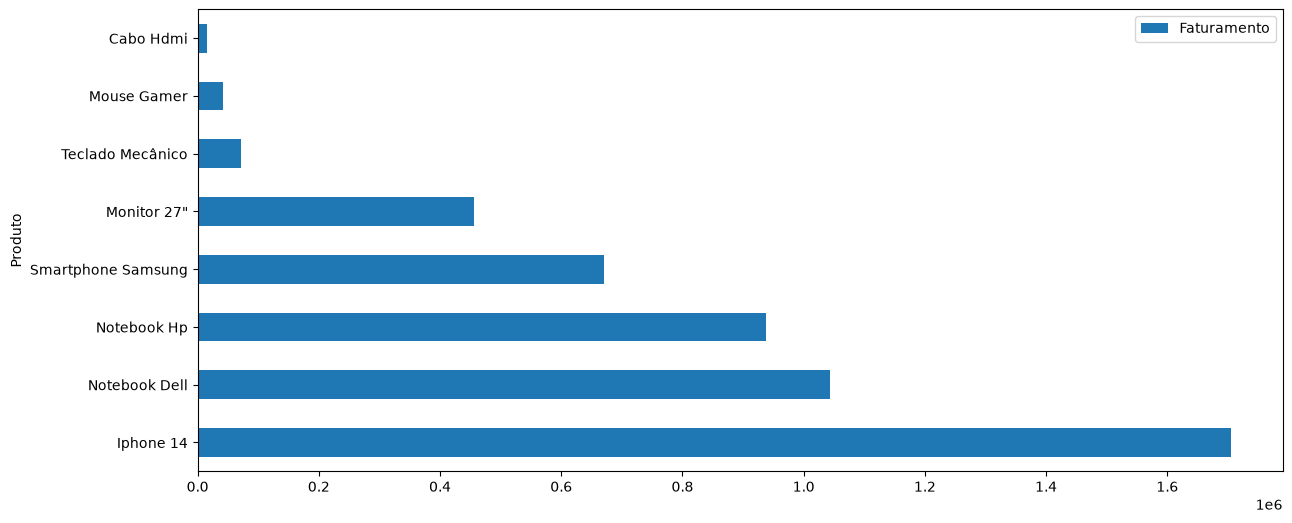

In [46]:
from pandas import DataFrame
import pandas
import matplotlib.pyplot as plot

dataframe_vendas = pandas.read_csv("../vendas_tech.csv", low_memory=False)
dataframe_vendas.drop_duplicates(subset="ID_Pedido")
dataframe_vendas = dataframe_vendas.dropna(subset=["Loja"])
dataframe_vendas = dataframe_vendas.rename(columns={"Qtd": "Quantidade"})
dataframe_vendas = dataframe_vendas[
    ["Data", "Loja", "Produto", "Preco_Unitario", "Quantidade"]
]
dataframe_vendas["Data"] = pandas.to_datetime(
    dataframe_vendas["Data"], format="%Y-%m-%d"
)
dataframe_vendas["Loja"] = dataframe_vendas["Loja"].str.strip().str.title()
dataframe_vendas["Produto"] = dataframe_vendas["Produto"].str.strip().str.title()

dataframe_vendas_jul_2023: DataFrame = dataframe_vendas[
    (dataframe_vendas["Data"].dt.year == 2023)
    & (dataframe_vendas["Data"].dt.month == 7)
]

dicionario_regioes = {
    "Curitiba": "Sul",
    "Recife": "Nordeste",
    "Porto Alegre": "Sul",
    "Belo Horizonte": "Sudeste",
    "Salvador": "Nordeste",
    "São Paulo": "Sudeste",
    "Rio De Janeiro": "Sudeste",
}

dataframe_vendas_jul_2023["Regiao"] = dataframe_vendas_jul_2023["Loja"].map(
    dicionario_regioes
)

dataframe_vendas_jul_2023_sudeste = dataframe_vendas_jul_2023[
    dataframe_vendas_jul_2023["Regiao"] == "Sudeste"
]

dataframe_vendas_jul_2023_sudeste["Faturamento"] = (
    dataframe_vendas_jul_2023_sudeste["Preco_Unitario"]
    * dataframe_vendas_jul_2023_sudeste["Quantidade"]
)

dataframe_vendas_jul_2023_sudeste = dataframe_vendas_jul_2023_sudeste[
    ["Produto", "Faturamento"]
]

dataframe_faturamento_jul_2023_sudeste = dataframe_vendas_jul_2023_sudeste.groupby(
    "Produto"
).sum()
dataframe_faturamento_jul_2023_sudeste = (
    dataframe_faturamento_jul_2023_sudeste.sort_values(
        by="Faturamento", ascending=False
    )
)

dataframe_faturamento_jul_2023_sudeste.plot.barh(figsize=(14, 6))

plot.savefig("faturamento_por_produto_jul_2023_regiao_sudeste.png")
